# NB 05 · Scénario 4 : Guerre de l'information

**Situation :** dans un conflit moderne, l'information est une arme. La cellule reçoit deux demandes :
1. **« Peut-on détecter automatiquement la désinformation et la propagande ? »** C'est le volet A, un détecteur entraîné sur 66 000 textes.
2. **« Comment chaque camp raconte-t-il le même événement ? »** C'est le volet B, la destruction du barrage de Kakhovka vue par les médias d'État russes et par la presse ukrainienne.

**Le parallèle avec God's Eye :** souviens-toi du cas du **port de Beyrouth**. Un modèle excellent sur ses données d'entraînement s'effondrait sur des images d'une autre source (*data shift*). On va retrouver exactement ce phénomène sur du texte, et le **dire franchement**. Dans le monde de la défense, un analyste qui connaît les limites de son outil vaut plus qu'un outil qui promet 99 %.

> Tout tourne sur processeur : TF-IDF et régression logistique, environ 2 minutes au total. C'est la base de référence classique, rapide et **explicable** : on peut lire les mots qui font décider le modèle.

In [1]:
import sys
from pathlib import Path

# On retrouve la racine du projet (le dossier qui contient data_lake/) pour importer src/
RACINE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_lake").is_dir())
sys.path.insert(0, str(RACINE / "src"))

import re
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import HTML, display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

from spirit_digger.config import OUTPUTS
from spirit_digger.loaders import charger
from spirit_digger.style import ACCENT, ALERTE, FOND, OK, TEXTE, VEILLE, bandeau, theme_ops

theme_ops()
pd.set_option("display.max_colwidth", 110)
bandeau("NB 05 · Guerre de l'information", "Détecter la propagande… et connaître les limites du détecteur.", niveau="ALERTE")


def entrainer(textes, etiquettes, nom):
    """TF-IDF (mots et paires de mots) + régression logistique, évalués sur 20 % de textes jamais vus."""
    x_train, x_test, y_train, y_test = train_test_split(textes, etiquettes, test_size=0.2, random_state=7,
                                                        stratify=etiquettes)
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_features=200_000, sublinear_tf=True)
    clf = LogisticRegression(max_iter=2000, C=4).fit(vec.fit_transform(x_train), y_train)
    pred = clf.predict(vec.transform(x_test))
    print(f"{nom} : exactitude {accuracy_score(y_test, pred):.1%} sur {len(y_test):,} textes de test")
    return vec, clf, y_test, pred


def mots_decisifs(vec, clf, classe, n=15):
    """Les n mots qui poussent le plus le modèle vers une classe."""
    noms = vec.get_feature_names_out()
    i = list(clf.classes_).index(classe)
    coef = clf.coef_[0] * (1 if i == 1 else -1) if len(clf.classes_) == 2 else clf.coef_[i]
    return list(noms[np.argsort(coef)[::-1][:n]])

# VOLET A · Le détecteur

## A1. Le modèle « tricheur »

On entraîne d'abord un modèle sur les textes **bruts**, sans le nettoyage du NB 01, pour distinguer *fiable* de *désinformation*. Puis on regarde **sur quels mots** il s'appuie.

In [2]:
vrai = charger("misinfo_true")["text"].fillna("")
faux = charger("misinfo_fake")["text"].fillna("")
brut = pd.DataFrame({"texte": pd.concat([vrai, faux], ignore_index=True),
                     "label": ["fiable"] * len(vrai) + ["desinformation"] * len(faux)})
brut = brut[brut["texte"].str.len() >= 100].drop_duplicates("texte")

vec_t, clf_t, _, _ = entrainer(brut["texte"], brut["label"], "Modèle tricheur (textes bruts)")
pd.DataFrame({"→ « désinformation »": mots_decisifs(vec_t, clf_t, "desinformation"),
              "→ « fiable »": mots_decisifs(vec_t, clf_t, "fiable")})

Modèle tricheur (textes bruts) : exactitude 95.7% sur 13,352 textes de test


,→ « désinformation »,→ « fiable »
0,via,said
1,read more,said on
2,featured image,president donald
3,image,on
4,featured,on twitter
5,image via,follow
6,twitter com,on tuesday
7,2016,on thursday
8,the us,on monday
9,com,on friday


**Le diagnostic :** « featured image », « getty images », « image via », « read more »… Le modèle a appris à reconnaître les **crédits photo et les menus des sites de fake news**, pas le mensonge. Face à un faux article sans crédit photo, il serait aveugle. C'est la fuite de données (*data leakage*) détectée au NB 00.

## A2. Le modèle propre, trois classes

On utilise maintenant le jeu nettoyé au NB 01. Les signatures de source sont retirées, et la classe **propagande d'État** a été correctement séparée. Les textes de propagande sont environ 10 fois plus courts : pour que la **longueur** ne trahisse pas la classe, on coupe **tous** les textes à 400 caractères. Le combat se fait à armes égales.

In [3]:
jeu = pd.read_parquet(OUTPUTS / "entrainement_infowar.parquet")
print(jeu["label"].value_counts().to_dict())
vec, clf, y_test, pred = entrainer(jeu["texte"].str[:400], jeu["label"], "Modèle propre, 3 classes (400 caractères)")
print()
print(classification_report(y_test, pred, digits=3))

{'fiable': 34135, 'desinformation': 27233, 'propagande_etat': 4867}


Modèle propre, 3 classes (400 caractères) : exactitude 91.1% sur 13,247 textes de test

                 precision    recall  f1-score   support

 desinformation      0.892     0.901     0.896      5447
         fiable      0.919     0.925     0.922      6827
propagande_etat      0.971     0.866     0.916       973

       accuracy                          0.911     13247
      macro avg      0.927     0.897     0.911     13247
   weighted avg      0.911     0.911     0.911     13247



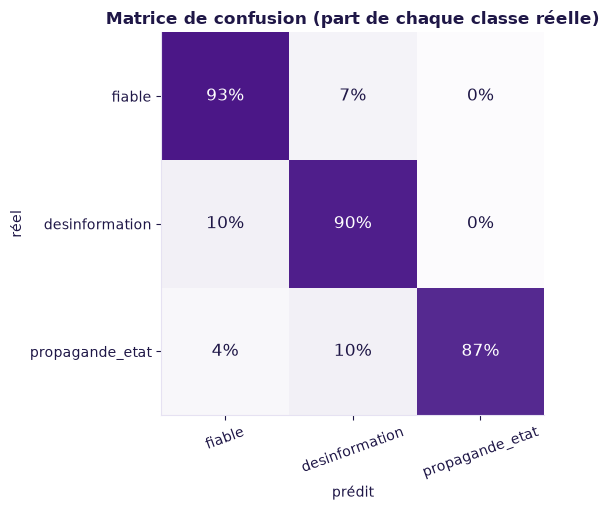

In [4]:
CLASSES = ["fiable", "desinformation", "propagande_etat"]
cm = confusion_matrix(y_test, pred, labels=CLASSES, normalize="true")
fig, ax = plt.subplots(figsize=(6.5, 5.2))
ax.imshow(cm, cmap="Purples", vmin=0, vmax=1)
ax.set_xticks(range(3), CLASSES, rotation=20)
ax.set_yticks(range(3), CLASSES)
ax.set_xlabel("prédit")
ax.set_ylabel("réel")
ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > 0.6 else TEXTE, fontsize=12)
ax.set_title("Matrice de confusion (part de chaque classe réelle)")
plt.tight_layout()
plt.show()

## A3. Que regarde vraiment le modèle ?

In [5]:
pd.DataFrame({c: mots_decisifs(vec, clf, c, 18) for c in CLASSES})

,fiable,desinformation,propagande_etat
0,said,2016,ukraine
1,president donald,trump,ukrainian
2,said on,november,russia
3,on,october,us
4,mr,obama,nato
5,friday,email,the us
6,tuesday,just,russian
7,thursday,november 2016,europe
8,president,print,european
9,wednesday,hillary,the


**Lecture analyste, la plus importante du notebook :**
- **« fiable »** s'appuie sur le **style d'agence** : « said on Tuesday », « said in a statement ». Ce sont des tournures, pas des faits vérifiés.
- **« désinformation »** s'appuie sur **l'époque** : « 2016 », « november », « october », « Hillary », « Obama », « email ». S'y ajoute un style de blog (« just », « this », « our », « via »). Les faux articles du jeu ont été collectés pendant la présidentielle américaine de 2016, les vrais surtout en 2017. Le modèle a en partie appris **une date**.
- **« propagande d'État »** s'appuie sur des **sujets** : Ukraine, OTAN, Crimée, Géorgie, Skripal, République tchèque. Ce sont les thèmes favoris de la propagande pro-Kremlin recensés par EUvsDisinfo. Encore une fois, ce sont des *sujets*, pas des mensonges : un article honnête sur la Crimée risque d'être classé propagande.

Le détecteur reconnaît **un style**, il ne vérifie **aucun fait**. Mettons-le à l'épreuve.

## A4. Crash-test : trois phrases piégées

In [6]:
PIEGES = [
    ("MENSONGE, style agence",
     "WASHINGTON - The Pentagon said on Tuesday that Iranian forces had seized the Eiffel Tower in Paris, "
     "according to two U.S. officials who spoke on condition of anonymity."),
    ("FAIT RÉEL, style racoleur",
     "WATCH: Iran just closed the Strait of Hormuz and oil prices are exploding. You won't believe what happened "
     "next. Read more via Twitter."),
    ("FAIT RÉEL, style agence",
     "The International Atomic Energy Agency said on Monday that Iran had enriched uranium to 60 percent purity "
     "at its Fordow facility, a spokesman said in a statement."),
]
proba = clf.predict_proba(vec.transform([t[:400] for _, t in PIEGES]))
resultats = pd.DataFrame(proba, columns=clf.classes_)[CLASSES]
resultats.insert(0, "phrase", [nom for nom, _ in PIEGES])
resultats["verdict du modèle"] = resultats[CLASSES].idxmax(axis=1)
resultats.style.format({c: "{:.0%}" for c in CLASSES}).background_gradient(subset=CLASSES, cmap="Purples").hide(axis="index")

phrase,fiable,desinformation,propagande_etat,verdict du modèle
"MENSONGE, style agence",100%,0%,0%,fiable
"FAIT RÉEL, style racoleur",1%,98%,1%,desinformation
"FAIT RÉEL, style agence",100%,0%,0%,fiable


**Le mensonge sur la tour Eiffel passe pour fiable**, simplement parce qu'il est rédigé comme une dépêche. Un vrai fait raconté en style racoleur est classé désinformation. N'importe quel acteur de propagande un peu sérieux contourne ce détecteur **en soignant sa forme**.

## A5. Dérive temporelle : le modèle de 2017 face à la presse de 2026

On applique le modèle aux 2 200 articles de presse du théâtre GOLFE (2026), écrits par des médias reconnus. On sait qu'il ne s'agit **pas** de désinformation. Tout article signalé est donc une **erreur du modèle**.

Articles de 2026 signalés à tort comme désinformation : 22%


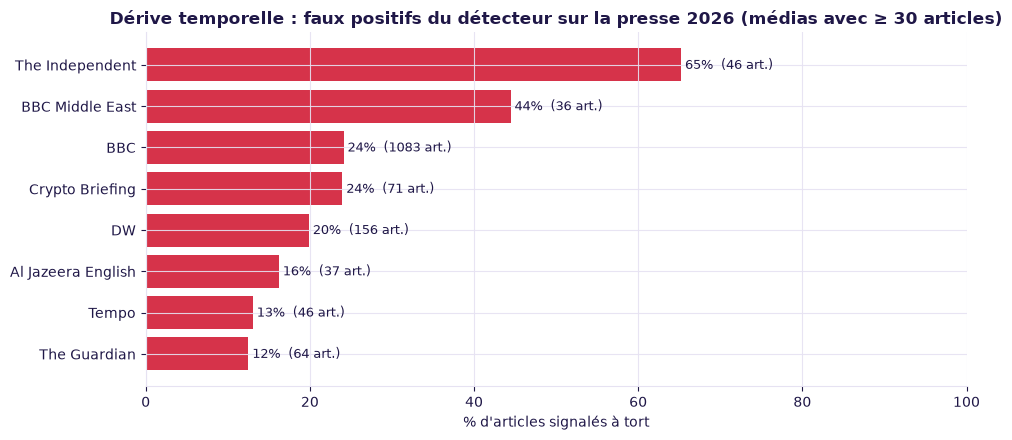

In [7]:
golfe = pd.read_parquet(OUTPUTS / "corpus_golfe.parquet")
golfe = golfe[golfe["langue"] == "en"].copy()
golfe["proba_desinfo"] = clf.predict_proba(vec.transform(golfe["texte"].str[:400]))[:, list(clf.classes_).index("desinformation")]
golfe["signale"] = golfe["proba_desinfo"] > 0.5

print(f"Articles de 2026 signalés à tort comme désinformation : {golfe['signale'].mean():.0%}")
erreurs = (golfe.groupby("source").agg(articles=("signale", "size"), faux_positifs=("signale", "mean"))
                .query("articles >= 30").sort_values("faux_positifs"))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(erreurs.index, erreurs["faux_positifs"] * 100, color=ALERTE)
for y, (v, n) in enumerate(zip(erreurs["faux_positifs"], erreurs["articles"])):
    ax.text(v * 100, y, f" {v:.0%}  ({n} art.)", va="center", fontsize=9)
ax.set_xlabel("% d'articles signalés à tort")
ax.set_title("Dérive temporelle : faux positifs du détecteur sur la presse 2026 (médias avec ≥ 30 articles)")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

**C'est notre « cas Beyrouth ».** Le modèle affiche 91 % d'exactitude sur son jeu de test, mais il signale à tort **environ un article sur cinq** de la presse de 2026, et jusqu'à près des deux tiers pour certains médias de référence. Le vocabulaire, les sujets et les styles ont changé depuis 2016-2017 : c'est la **dérive temporelle** (*concept drift*).

### Verdict du volet A

| Ce qu'on montre | Ce qu'on en conclut |
|---|---|
| **Modèle tricheur** : il apprend les crédits photo | Toujours chercher les fuites avant de croire un score |
| **Modèle propre** : 91 % d'exactitude en test | Le chiffre de laboratoire ne dit rien du terrain |
| **Crash-test** : le style trompe le modèle | Il détecte une **forme**, pas la **vérité** |
| **Dérive temporelle** : environ 1 article sur 5 signalé à tort en 2026 | Un détecteur figé vieillit ; il faut le réentraîner en continu |

**Conséquence pour Spirit Digger :** la fiabilité d'une information ne se juge pas à son style, mais au **recoupement par des sources indépendantes**. C'est exactement ce que fait le score de convergence des camps du NB 03, et ce que fera la cotation du bulletin au NB 06. Le détecteur reste utile pour une seule chose : **trier** un flux et signaler des textes à relire en priorité, jamais pour conclure.

---

# VOLET B · Un événement, deux récits

## B1. Préparer les messages : retirer les pieds de message

Au NB 03, on a vu qu'UNIAN ajoute « Остаться с нами в Телеграм » à chaque message. Avant de comparer les vocabulaires, on retire **automatiquement** ces pieds de message. Méthode : une même fin de message répétée au moins 50 fois par une chaîne est une signature, pas du contenu.

In [8]:
telegram = pd.read_parquet(OUTPUTS / "corpus_ukraine.parquet", columns=["date", "source", "camp", "texte"])

fins = telegram["texte"].str.extract(r"([^.!?]{8,90})$")[0].str.strip()
frequentes = pd.DataFrame({"chaîne": telegram["source"], "pied de message": fins}).dropna().value_counts()
PIEDS = frequentes[frequentes >= 50]
pieds_par_chaine = defaultdict(list)
for (chaine, pied), _ in PIEDS.items():
    pieds_par_chaine[chaine].append(pied)


def sans_pied(chaine, texte):
    for pied in pieds_par_chaine.get(chaine, []):
        if texte.endswith(pied):
            return texte[: -len(pied)].rstrip(" /|.")
    return texte


telegram["texte"] = [sans_pied(c, t) for c, t in zip(telegram["source"], telegram["texte"])]
print(f"{len(PIEDS)} pieds de message détectés. Les plus fréquents :")
PIEDS.head(8).rename("messages").to_frame()

54 pieds de message détectés. Les plus fréquents :


,,messages
chaîne,pied de message,
Ukraine Now,Украина Сейчас,32313
Shocked Ukraine,Подписаться,15289
УНИАН,Остаться с нами в Телеграм | Восхититься нашим YouTube,7558
Ukraine Now,Украина Сейчас / Подписаться,5632
УНИАН,Подписаться на Новости УНИАН | #новости,2432
Ukraine Now,Подписаться / Прислать новость,2162
TASS,Видео: ТАСС/Ruptly,1655
УНИАН,Подписаться на канал УНИАН,1549


## B2. Le vocabulaire de chaque camp : la méthode des « mots de combat »

Pour l'événement choisi, on compare les messages des **médias d'État russes** (TASS, RIA) et ceux des **chaînes ukrainiennes**. Pour chaque mot, on calcule un **log-odds ratio** : il est positif si le mot est caractéristique d'un camp, négatif s'il l'est de l'autre. On le divise par son incertitude, puis on lisse avec la fréquence générale du mot, pour qu'un mot rare ne domine pas par hasard. C'est la méthode des *Fightin' Words* (Monroe et al., 2008), très utilisée en analyse du discours politique.

In [9]:
MOT = re.compile(r"[а-яёіїєґ]{4,}")
MOTS_OUTILS = set("""больше того через чтобы если после также будет будут этого этом есть было были может сейчас
более когда только который которые которая которых всех свои своей него этой этот эти очень даже однако ними
можно нужно себя всего между здесь там тоже потому где какие какой""".split())


def presence(textes):
    c = Counter()
    for t in textes:
        c.update(set(MOT.findall(t.lower())) - MOTS_OUTILS)
    return c


FOND_LEXICAL = presence(telegram["texte"].sample(60_000, random_state=1))


def mots_de_combat(messages, camp_a, camp_b, n=15, min_occ=6):
    a = presence(messages.loc[messages["camp"] == camp_a, "texte"])
    b = presence(messages.loc[messages["camp"] == camp_b, "texte"])
    na, nb = (messages["camp"] == camp_a).sum(), (messages["camp"] == camp_b).sum()
    lignes = []
    for w in set(a) | set(b):
        if a[w] + b[w] < min_occ:
            continue
        prior = 10 * (FOND_LEXICAL[w] + 1) / 60_000          # lissage par la fréquence générale du mot
        pa, pb = (a[w] + prior) / (na + 10), (b[w] + prior) / (nb + 10)
        z = (np.log(pa / (1 - pa)) - np.log(pb / (1 - pb))) / np.sqrt(1 / (a[w] + prior) + 1 / (b[w] + prior))
        lignes.append((w, z, a[w] / na, b[w] / nb))
    df = pd.DataFrame(lignes, columns=["mot", "z", "part_a", "part_b"]).sort_values("z")
    return df.tail(n).iloc[::-1], df.head(n)

## B3. Kakhovka, 6-9 juin 2023

Messages des 4 jours qui suivent la destruction du barrage, mentionnant Kakhovka, le barrage, la digue ou la centrale (ГЭС).

In [10]:
GLOSSAIRE = {
    "подрыва": "dynamitage", "подрыв": "dynamitage", "дамбы": "digue", "дамбу": "digue", "дамба": "digue",
    "водой": "eau", "взорвали": "ont fait sauter", "российские": "russes", "российскими": "par les Russes",
    "каховская": "de Kakhovka", "разрушена": "détruite", "последствий": "conséquences",
    "снбо": "Conseil de sécurité ukr. (SNBO)", "укргидроэнерго": "Ukrhydroenergo (exploitant)",
    "херсона": "Kherson", "оккупантами": "par les occupants", "оккупанты": "les occupants",
    "оккупантов": "des occupants", "рашисты": "« rashistes » (péjoratif)", "россияне": "les Russes",
    "россиянами": "par les Russes", "экоцид": "écocide", "плотину": "barrage", "херсонщины": "région de Kherson",
    "каховской": "de Kakhovka", "сообщил": "a annoncé", "сообщили": "ont annoncé", "разрушения": "destruction",
    "области": "région", "владимир": "Vladimir (Saldo)", "херсонской": "de Kherson", "новой": "Nova (Kakhovka)",
    "заявил": "a déclaré", "каховки": "Kakhovka", "каховке": "Kakhovka", "власти": "autorités", "воды": "eau",
    "леонтьев": "Leontiev (maire installé par Moscou)", "региона": "région", "администрации": "administration",
    "новости": "nouvelles", "сальдо": "Saldo (gouverneur installé par Moscou)", "удар": "frappe",
    "режим": "régime", "врио": "par intérim", "губернатора": "gouverneur", "прорыва": "rupture",
    "экстренных": "d'urgence", "заявления": "déclarations", "собрали": "ont rassemblé", "путин": "Poutine",
    "председатель": "président", "связи": "lien / à cause de", "эвакуации": "évacuation",
    "украина": "Ukraine", "затопления": "inondation", "подтоплены": "submergés", "жителей": "habitants",
}

kakhovka = telegram[(telegram["date"] >= "2023-06-06") & (telegram["date"] <= "2023-06-09")
                    & telegram["texte"].str.lower().str.contains("каховск|плотин|дамб|гэс")]
print(kakhovka["camp"].value_counts().to_dict())

russie, ukraine = mots_de_combat(kakhovka, "Russie - État", "Ukraine")


def colonne(df, cle):
    return [f"{m}  ({GLOSSAIRE.get(m, '–')})  {p:.0%}" for m, p in zip(df["mot"], df[cle])]


pd.DataFrame({"RUSSIE - ÉTAT (TASS, RIA) : mot · traduction · % messages": colonne(russie, "part_a"),
              "UKRAINE (UNIAN, Ukraine Now…) : mot · traduction · % messages": colonne(ukraine, "part_b")})

{'Ukraine': 331, 'Russie - État': 268, 'Russe indépendant (exil)': 122, 'International': 120, 'Russie - presse sous contrainte': 75}


,"RUSSIE - ÉTAT (TASS, RIA) : mot · traduction · % messages","UKRAINE (UNIAN, Ukraine Now…) : mot · traduction · % messages"
0,каховской (de Kakhovka) 89%,подрыва (dynamitage) 32%
1,сообщил (a annoncé) 29%,дамбы (digue) 24%
2,разрушения (destruction) 34%,подрыв (dynamitage) 14%
3,области (région) 33%,водой (eau) 9%
4,владимир (Vladimir (Saldo)) 20%,взорвали (ont fait sauter) 6%
5,херсонской (de Kherson) 29%,российские (russes) 8%
6,новой (Nova (Kakhovka)) 20%,российскими (par les Russes) 5%
7,заявил (a déclaré) 27%,дамбу (digue) 5%
8,сообщили (ont annoncé) 13%,каховская (de Kakhovka) 5%
9,каховки (Kakhovka) 14%,разрушена (détruite) 4%


**Deux récits du même événement :**
- **Côté ukrainien**, le récit est celui d'un **acte délibéré avec un coupable** : « dynamitage », « ont fait sauter », « par les Russes », « détruite ». Il s'appuie sur les institutions ukrainiennes (le Conseil de sécurité SNBO, l'exploitant Ukrhydroenergo).
- **Côté État russe**, le récit est **administratif et humanitaire** : « a annoncé », « autorités », « administration », « destruction », « eau ». Il est porté par les responsables installés par Moscou (Saldo, Leontiev). Le coupable n'est pas nommé, mais le mot « frappe » laisse entendre une action ukrainienne.

C'est un résultat classique en analyse du discours : **désigner un coupable** d'un côté, **parler des conséquences** de l'autre.

## B4. Qui est désigné ?

On mesure, pour chaque camp, la part des messages qui emploient chaque type de vocabulaire.

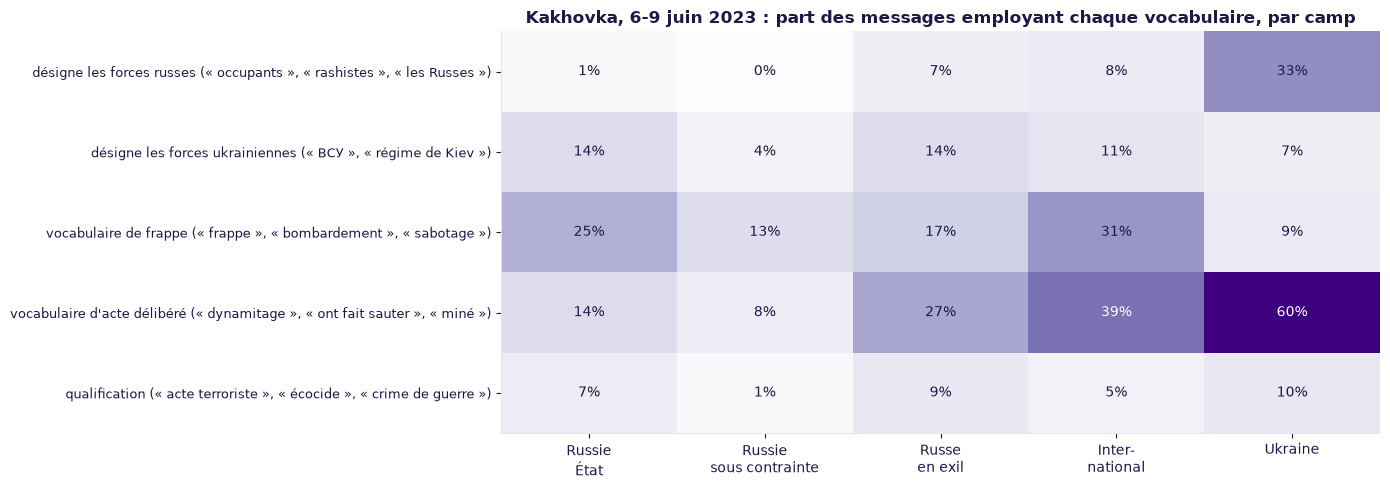

In [11]:
# Attention : avec pandas 3, str.contains utilise le moteur RE2, pour lequel « \b » ne reconnaît que
# l'alphabet latin. En cyrillique, on écrit donc la frontière de mot explicitement.
D = r"(?:^|[^а-яёіїєґ])"       # début de mot
F = r"(?:[^а-яёіїєґ]|$)"       # fin de mot
MARQUEURS = {
    "désigne les forces russes (« occupants », « rashistes », « les Russes »)": r"оккупант|рашист|россиян",
    "désigne les forces ukrainiennes (« ВСУ », « régime de Kiev »)": D + "всу" + F + r"|киевск\w* режим",
    "vocabulaire de frappe (« frappe », « bombardement », « sabotage »)": D + r"удар|обстрел|диверси",
    "vocabulaire d'acte délibéré (« dynamitage », « ont fait sauter », « miné »)": r"подрыв|подорвал|взорвал|заминир",
    "qualification (« acte terroriste », « écocide », « crime de guerre »)": r"теракт|экоцид|военн\w* преступлен",
}
ORDRE_CAMPS = ["Russie - État", "Russie - presse sous contrainte", "Russe indépendant (exil)", "International", "Ukraine"]
qui = pd.DataFrame({camp: {nom: kakhovka.loc[kakhovka["camp"] == camp, "texte"].str.lower().str.contains(motif).mean()
                           for nom, motif in MARQUEURS.items()} for camp in ORDRE_CAMPS})

fig, ax = plt.subplots(figsize=(14, 5))
ax.imshow(qui.values, cmap="Purples", aspect="auto", vmin=0, vmax=qui.values.max())
COURT = {"Russie - État": "Russie\nÉtat", "Russie - presse sous contrainte": "Russie\nsous contrainte",
         "Russe indépendant (exil)": "Russe\nen exil", "International": "Inter-\nnational", "Ukraine": "Ukraine"}
ax.set_xticks(range(len(ORDRE_CAMPS)), [COURT[c] for c in ORDRE_CAMPS])
ax.set_yticks(range(len(qui)), qui.index, fontsize=9)
ax.grid(False)
for (i, j), v in np.ndenumerate(qui.values):
    ax.text(j, i, f"{v:.0%}", ha="center", va="center", color="white" if v > qui.values.max() * 0.6 else TEXTE)
ax.set_title("Kakhovka, 6-9 juin 2023 : part des messages employant chaque vocabulaire, par camp")
plt.tight_layout()
plt.savefig(OUTPUTS / "05_kakhovka_recits.png", dpi=130)
plt.show()

**Lecture : chaque camp accuse l'autre.**
- **Les chaînes ukrainiennes** désignent les forces russes dans **un message sur trois** (« occupants », « rashistes ») et décrivent un **acte délibéré** dans 60 % des cas (« dynamitage », « ont fait sauter »).
- **Les médias d'État russes** ne nomment pratiquement jamais les forces russes (1 %). Ils désignent les **forces ukrainiennes** (« ВСУ », 14 %) et parlent de **frappes** (25 %) : c'est la thèse d'un tir ukrainien sur la centrale.
- **Les médias en exil et internationaux** citent les deux versions et parlent beaucoup du dynamitage. C'est la prudence journalistique d'avant l'attribution officielle.

En quelques secondes de calcul, la cellule obtient la **carte des narratifs** d'un événement. C'est la matière première d'un analyste en lutte informationnelle.

## B5. Qui en parle, qui se tait ?

Le **silence** est aussi un signal. Quelle part de son antenne chaque camp a-t-il consacrée à l'événement ?

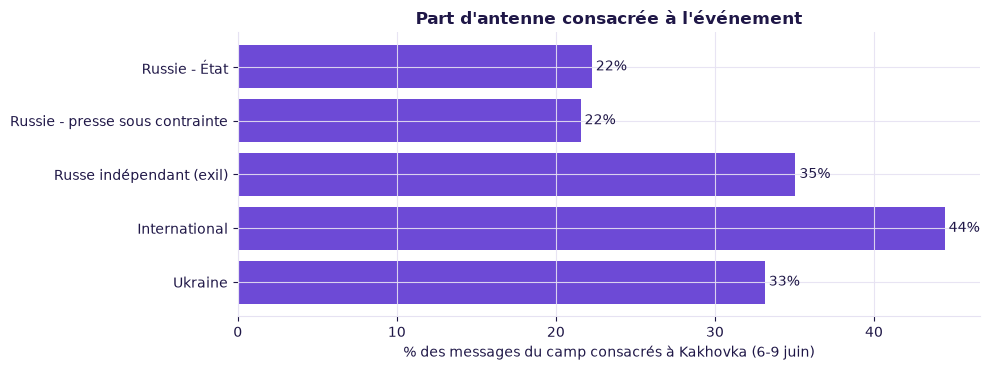

In [12]:
fenetre = telegram[(telegram["date"] >= "2023-06-06") & (telegram["date"] <= "2023-06-09")]
couverture = (kakhovka.groupby("camp").size() / fenetre.groupby("camp").size()).reindex(ORDRE_CAMPS)
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(couverture.index[::-1], couverture.values[::-1] * 100, color=ACCENT)
for y, v in enumerate(couverture.values[::-1]):
    ax.text(v * 100, y, f" {v:.0%}", va="center")
ax.set_xlabel("% des messages du camp consacrés à Kakhovka (6-9 juin)")
ax.set_title("Part d'antenne consacrée à l'événement")
plt.tight_layout()
plt.show()

**Lecture :** la plus grande catastrophe écologique du conflit occupe environ **un message sur cinq** dans les médias russes, contre **un sur trois** dans la presse ukrainienne et en exil, et davantage encore chez les médias internationaux. Les médias russes en parlent, mais **moins**. La sous-couverture est un choix éditorial, et donc un indice.

## B6. À toi de jouer : un autre événement

La fonction est générique. Voici la **mutinerie Wagner** (23-25 juin 2023). On complète le glossaire pour l'occasion ; avec un modèle de traduction automatique ou un LLM, cette étape serait automatique.

In [13]:
GLOSSAIRE.update({
    "вагнер": "Wagner", "россии": "Russie", "вооруженного": "armée (mutinerie armée)", "ситуации": "situation",
    "мятежа": "mutinerie", "дону": "(Rostov-sur-le-)Don", "евгения": "Evgueni", "президента": "président",
    "глава": "chef", "пригожин": "Prigojine", "вагнеровцы": "les wagnériens", "вагнеровцев": "des wagnériens",
    "москву": "Moscou", "ростов": "Rostov", "шойгу": "Choïgou", "сообщают": "on rapporte", "сообщается": "il est rapporté",
    "пока": "pour l'instant", "сторону": "côté", "тысяч": "milliers", "теперь": "désormais", "кроме": "en dehors de",
})
wagner = telegram[(telegram["date"] >= "2023-06-23") & (telegram["date"] <= "2023-06-25")
                  & telegram["texte"].str.lower().str.contains("пригожин|вагнер|мятеж")]
r_w, u_w = mots_de_combat(wagner, "Russie - État", "Ukraine", n=12)
pd.DataFrame({"RUSSIE - ÉTAT": colonne(r_w, "part_a"), "UKRAINE": colonne(u_w, "part_b")})

,RUSSIE - ÉTAT,UKRAINE
0,вагнер (Wagner) 59%,пригожин (Prigojine) 24%
1,россии (Russie) 30%,вагнеровцы (les wagnériens) 11%
2,сообщил (a annoncé) 15%,москву (Moscou) 6%
3,вооруженного (armée (mutinerie armée)) 14%,вагнеровцев (des wagnériens) 9%
4,ситуации (situation) 14%,ростов (Rostov) 5%
5,заявил (a déclaré) 19%,шойгу (Choïgou) 5%
6,мятежа (mutinerie) 17%,сообщают (on rapporte) 5%
7,дону ((Rostov-sur-le-)Don) 13%,сообщается (il est rapporté) 6%
8,евгения (Evgueni) 11%,пока (pour l'instant) 5%
9,президента (président) 11%,сторону (côté) 4%


**Lecture :** les médias d'État reprennent la **qualification officielle**, « mutinerie armée », celle du discours de Poutine, et un vocabulaire institutionnel (« président », « situation », « a annoncé »). Les chaînes ukrainiennes **personnalisent** (Prigojine, Choïgou, « les wagnériens »), suivent la **marche sur Moscou** et rapportent beaucoup **au conditionnel** (« on rapporte », « il est rapporté ») : c'est un récit en direct, sur des informations non confirmées.

## Sauvegarde pour le bulletin (NB 06)

In [14]:
pd.concat([russie.assign(camp="Russie - État", traduction=russie["mot"].map(GLOSSAIRE)),
           ukraine.assign(camp="Ukraine", traduction=ukraine["mot"].map(GLOSSAIRE))]).to_csv(
    OUTPUTS / "recits_kakhovka.csv", index=False)
qui.to_csv(OUTPUTS / "kakhovka_marqueurs.csv")
pd.DataFrame([{"exactitude_test": accuracy_score(y_test, pred),
               "faux_positifs_presse_2026": golfe["signale"].mean()}]).to_csv(OUTPUTS / "detecteur_bilan.csv", index=False)
print("recits_kakhovka.csv · kakhovka_marqueurs.csv · detecteur_bilan.csv · 05_kakhovka_recits.png")

recits_kakhovka.csv · kakhovka_marqueurs.csv · detecteur_bilan.csv · 05_kakhovka_recits.png


## Ce qu'il faut retenir

**Volet A, le détecteur :**
- Le modèle « tricheur » apprend les crédits photo. Le modèle propre apprend **le style et l'époque**.
- Excellent en laboratoire, il est **trompé par la forme** (la tour Eiffel « saisie » passe pour fiable) et **vieillit mal** (nombreux faux positifs sur la presse 2026).
- On l'utilise pour **trier**, jamais pour **juger**. Le jugement passe par le recoupement multi-sources.

**Volet B, les récits :**
- Sans traducteur et sans GPU, une méthode statistique simple fait apparaître **deux récits opposés** du même événement : un coupable désigné d'un côté, des conséquences administratives de l'autre.
- Le **silence** se mesure aussi : la part d'antenne consacrée à un événement est un indicateur.

> **Phrase de démo :** « Notre détecteur de désinformation affiche 91 % d'exactitude en laboratoire, et je vais vous montrer pourquoi il ne faut pas lui faire confiance. Un mensonge bien rédigé le trompe. Sur la presse de 2026, il se trompe massivement. C'est pour ça que Spirit Digger juge l'information par le recoupement, pas par le style. »

**Prochaine étape → NB 06 : corrélation et bulletin de renseignement.**